## NYC Trip Duration



This is notebook is doing **explanatory data analysis** on the nyc-trip_duration analysis. 

Data fields

    id - a unique identifier for each trip
    vendor_id - a code indicating the provider associated with the trip record
    pickup_datetime - date and time when the meter was engaged
    dropoff_datetime - date and time when the meter was disengaged
    passenger_count - the number of passengers in the vehicle (driver entered value)
    pickup_longitude - the longitude where the meter was engaged
    pickup_latitude - the latitude where the meter was engaged
    dropoff_longitude - the longitude where the meter was disengaged
    dropoff_latitude - the latitude where the meter was disengaged
    store_and_fwd_flag - This flag indicates whether the trip record was held in vehicle memory before sending to the vendor because the vehicle did not have a connection to the server - Y=store and forward; N=not a store and forward trip
    trip_duration - duration of the trip in seconds



In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # just one category


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
from pathlib import Path
out = Path("../reports")

In [3]:
df = pd.read_csv("train.csv", parse_dates=["pickup_datetime"])

In [ ]:

profile = ProfileReport(df, title="NYC Trip Duration - Profile", explorative=True)
profile.to_file(out / "profile.html")

You can check the file inside the Reports under Profile (Html Page)

In [4]:
df.drop(columns=["id"], inplace=True)

In [5]:
df.head()

,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,2,2016-06-08 07:36:19,1,-73.985611,40.735943,-73.980331,40.760468,N,1040
1,2,2016-04-03 12:58:11,1,-73.978394,40.764351,-73.991623,40.749859,N,827
2,2,2016-06-05 02:49:13,5,-73.989059,40.744389,-73.973381,40.748692,N,614
3,2,2016-05-05 17:18:27,2,-73.990326,40.731136,-73.991264,40.748917,N,867
4,1,2016-05-12 17:43:38,4,-73.789497,40.646675,-73.987137,40.759232,N,4967


In [6]:
df.insert(0, "year", df["pickup_datetime"].dt.year)
df.insert(1, "month", df["pickup_datetime"].dt.month)
df.insert(2, "hour", df["pickup_datetime"].dt.hour)
df.insert(3, "day_of_week", df["pickup_datetime"].dt.dayofweek)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   year                1000000 non-null  int32         
 1   month               1000000 non-null  int32         
 2   hour                1000000 non-null  int32         
 3   day_of_week         1000000 non-null  int32         
 4   vendor_id           1000000 non-null  int64         
 5   pickup_datetime     1000000 non-null  datetime64[ns]
 6   passenger_count     1000000 non-null  int64         
 7   pickup_longitude    1000000 non-null  float64       
 8   pickup_latitude     1000000 non-null  float64       
 9   dropoff_longitude   1000000 non-null  float64       
 10  dropoff_latitude    1000000 non-null  float64       
 11  store_and_fwd_flag  1000000 non-null  object        
 12  trip_duration       1000000 non-null  int64         
dtypes: datetime64

Vendor_id has two values only 1 or 2, so they are categorical. 

In [8]:
df['vendor_id'] = df['vendor_id'].astype('category')

In [9]:
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include=["object", "string"]).columns
num_cols

Index(['year', 'month', 'hour', 'day_of_week', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'trip_duration'],
      dtype='object')

In [10]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
year,1000000.0,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.0
month,1000000.0,3.515209,1.0,2.0,4.0,5.0,6.0,1.681171
hour,1000000.0,13.604165,0.0,9.0,14.0,19.0,23.0,6.400685
day_of_week,1000000.0,3.051486,0.0,1.0,3.0,5.0,6.0,1.954644
pickup_datetime,1000000,2016-04-01 08:53:15.180106752,2016-01-01 00:00:53,2016-02-17 15:26:08,2016-04-01 15:01:29.500000,2016-05-15 02:35:38.750000128,2016-06-30 23:59:37,NaN
passenger_count,1000000.0,1.665353,0.0,1.0,1.0,2.0,7.0,1.315723
pickup_longitude,1000000.0,-73.973475,-121.933342,-73.991852,-73.981728,-73.967346,-61.335529,0.065404
pickup_latitude,1000000.0,40.750947,34.359695,40.737372,40.754131,40.768379,51.881084,0.033745
dropoff_longitude,1000000.0,-73.973421,-121.933304,-73.991341,-73.979767,-73.963036,-61.335529,0.065432
dropoff_latitude,1000000.0,40.751829,34.359695,40.735928,40.754551,40.769833,43.921028,0.035782


**The Trip duration does seems to have outliers, the least duration trip is 1 second, and the maximum is 25 days (2 million seconds)**

25th percentile = 397s (\~6.6 min)

50th percentile (median) = 662s (\~11 min)

75th percentile = 1074s (\~18 min)

max = 2,227,612 seconds — that's about 25.8 days. Obviously not a real taxi trip either

std ≈ 3,882 — (about one hour) huge relative to the mean

In [11]:
print("Trips less than one minute and half:", (df['trip_duration'] < 100).sum()) 

print("Trips more than 3 hours and 30 minutes:", (df['trip_duration'] > 12_600).sum())  

Trips less than one minute and half: 12864
Trips more than 3 hours and 30 minutes: 1438


In [12]:
df_clean = df[(df['trip_duration'] >= 100) & (df['trip_duration'] <= 12600)]

In [13]:
df_clean['trip_duration'].describe()

count    985698.000000
mean        846.309856
std         656.914076
min         100.000000
25%         406.000000
50%         669.000000
75%        1080.000000
max       12527.000000
Name: trip_duration, dtype: float64

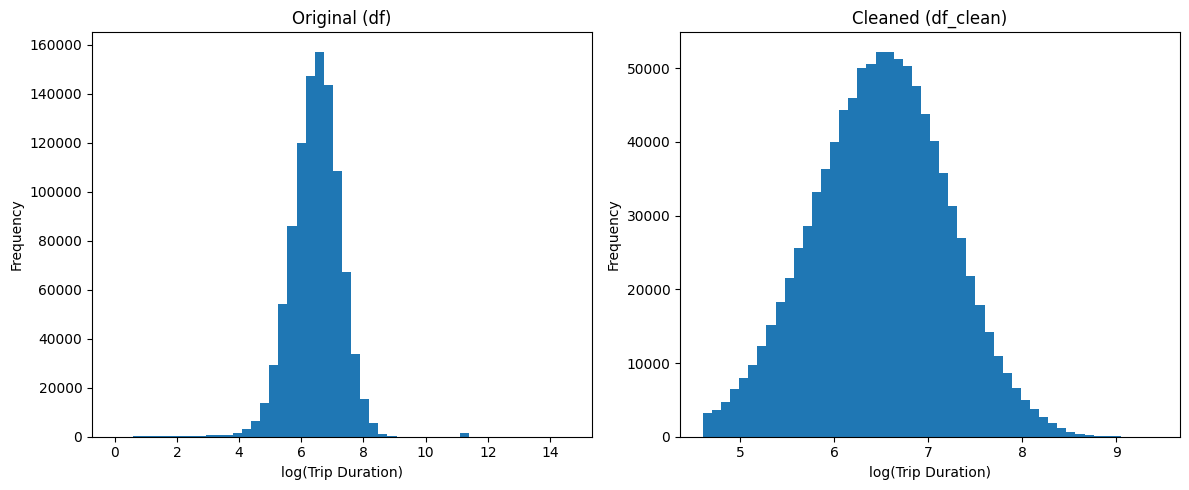

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(np.log(df['trip_duration']), bins=50)
axes[0].set_xlabel('log(Trip Duration)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Original (df)')

axes[1].hist(np.log(df_clean['trip_duration']), bins=50)
axes[1].set_xlabel('log(Trip Duration)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Cleaned (df_clean)')

plt.tight_layout()
plt.show()

In [15]:
print(f"The middle seems to be about ~{(np.exp(6.5)/60):.0f} minutes for the cleaned df")

The middle seems to be about ~11 minutes for the cleaned df


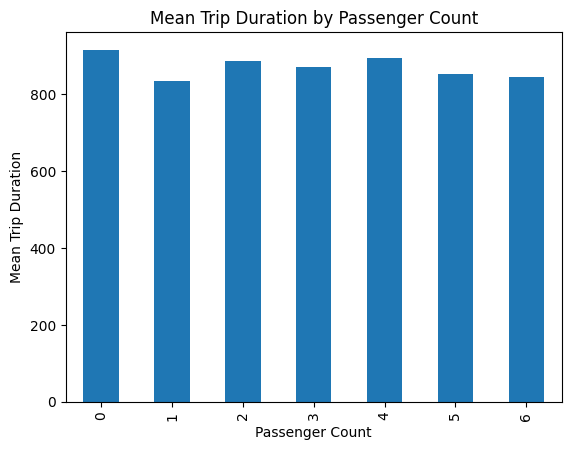

In [16]:
df_clean.groupby("passenger_count")["trip_duration"].mean().plot(kind='bar')
plt.xlabel('Passenger Count')
plt.ylabel('Mean Trip Duration')
plt.title('Mean Trip Duration by Passenger Count')
plt.show()

In [17]:
len(df_clean[df_clean['passenger_count'] <= 0]) # 0 passangers counts

7

In [18]:
df_clean = df_clean[df_clean['passenger_count'] > 0]

In [19]:
df["year"].value_counts()

year
2016    1000000
Name: count, dtype: int64

In [20]:
df_clean.drop(columns=['year', 'pickup_datetime'], inplace=True)

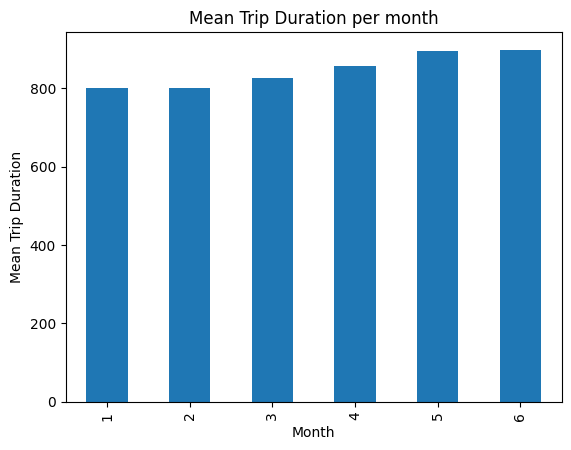

In [21]:
df_clean.groupby("month")["trip_duration"].mean().plot(kind='bar')
plt.xlabel('Month')
plt.ylabel('Mean Trip Duration')
plt.title('Mean Trip Duration per month')
plt.show()

The month seems no value

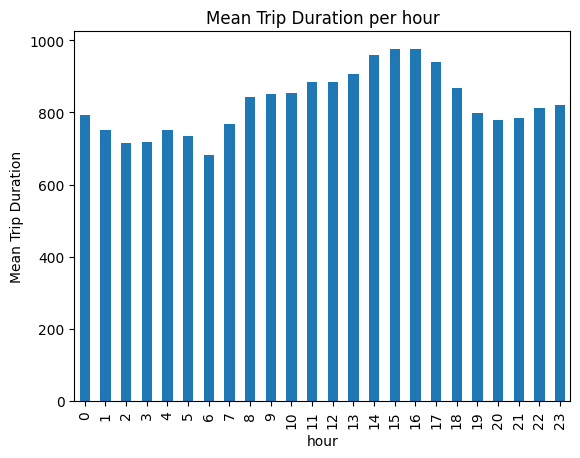

In [22]:
df_clean.groupby("hour")["trip_duration"].mean().plot(kind='bar')
plt.xlabel('hour')
plt.ylabel('Mean Trip Duration')
plt.title('Mean Trip Duration per hour')
plt.show()

In [23]:
# df_clean['is_rush_hour'] = df_clean['hour'].between(14, 16).astype(int)

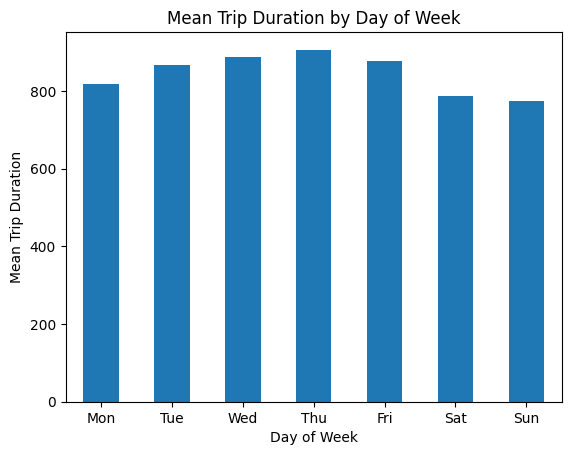

In [24]:
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

df_clean.groupby("day_of_week")["trip_duration"].mean().plot(kind='bar')
plt.xticks(ticks=range(7), labels=day_names, rotation=0)
plt.xlabel('Day of Week')
plt.ylabel('Mean Trip Duration')
plt.title('Mean Trip Duration by Day of Week')
plt.show()

In [25]:
num_cols = df_clean.select_dtypes(include='number').columns
cat_cols = df_clean.select_dtypes(include=["object", "string"]).columns
num_cols

Index(['month', 'hour', 'day_of_week', 'passenger_count', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'trip_duration'],
      dtype='object')

Delete it since no variance here.

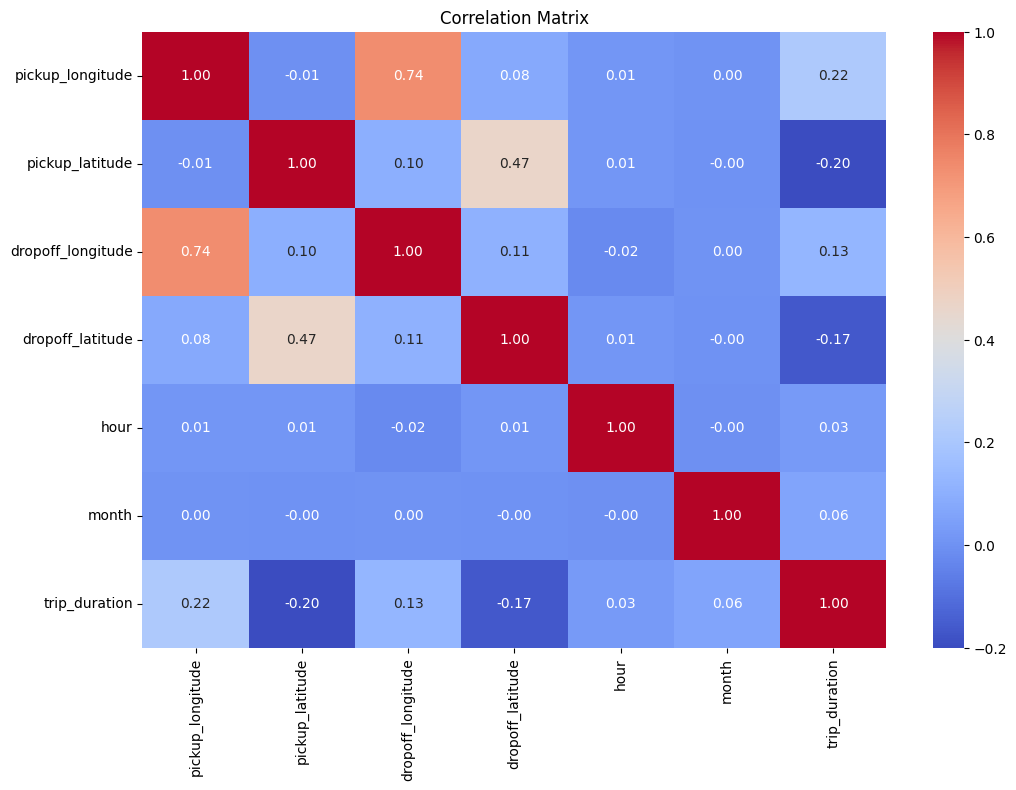

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation = df_clean[['pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude','hour', 'month',
       'trip_duration']].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [27]:
def add_time_features(df, day_of_week_start='monday'):
    """
    Add is_rush_hour, is_weekday, is_holiday based on hour/day_of_week/month.
    day_of_week_start: 'monday' (0=Mon...6=Sun) or 'sunday' (0=Sun...6=Sat)
    """
    df = df.copy()

    # Rush hour: 7-9am and 4-7pm
    df['is_rush_hour'] = (df['hour'].between(14, 16)).astype(int)

    # Weekday: depends on day_of_week encoding
    if day_of_week_start == 'monday':
        weekend_days = [5, 6]  # Sat, Sun
    elif day_of_week_start == 'sunday':
        weekend_days = [0, 6]  # Sun, Sat
    else:
        raise ValueError("day_of_week_start must be 'monday' or 'sunday'")

    df['is_weekday'] = (~df['day_of_week'].isin(weekend_days)).astype(int)

    return df

In [28]:
# df_clean['is_rush_hour'] = df_clean['hour'].between(14, 16).astype(int)

In [29]:
df_clean.head()

,month,hour,day_of_week,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,6,7,2,2,1,-73.985611,40.735943,-73.980331,40.760468,N,1040
1,4,12,6,2,1,-73.978394,40.764351,-73.991623,40.749859,N,827
2,6,2,6,2,5,-73.989059,40.744389,-73.973381,40.748692,N,614
3,5,17,3,2,2,-73.990326,40.731136,-73.991264,40.748917,N,867
4,5,17,3,1,4,-73.789497,40.646675,-73.987137,40.759232,N,4967


In [30]:
def add_haversine_distance(df, lat1='pickup_latitude', lon1='pickup_longitude',
                             lat2='dropoff_latitude', lon2='dropoff_longitude',
                             col_name='haversine_distance'):
    """
    Add great-circle distance (in km) between two lat/lon points.
    Uses the haversine formula.
    """
    df = df.copy()

    R = 6371  # Earth's radius in km

    lat1_r = np.radians(df[lat1])
    lat2_r = np.radians(df[lat2])
    dlat = np.radians(df[lat2] - df[lat1])
    dlon = np.radians(df[lon2] - df[lon1])

    a = np.sin(dlat / 2)**2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    df[col_name] = R * c

    return df

In [31]:
df_clean = add_haversine_distance(df_clean)

Text(0, 0.5, 'Trip Duration (s)')

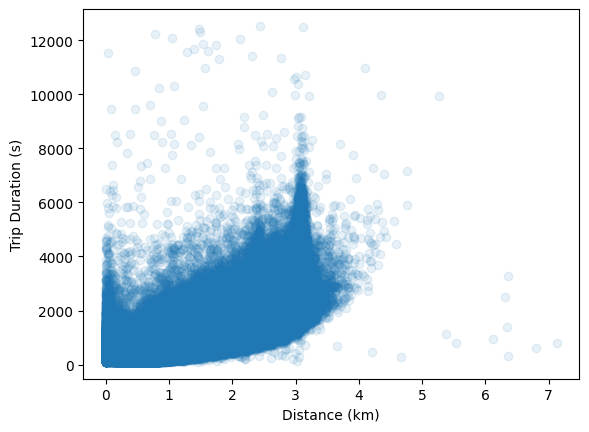

In [32]:
plt.scatter(np.log1p(df_clean['haversine_distance']), df_clean['trip_duration'], alpha=0.1)
plt.xlabel('Distance (km)')
plt.ylabel('Trip Duration (s)')

In [33]:
print(df_clean['haversine_distance'].describe())

count    985691.000000
mean          3.478054
std           4.431871
min           0.000000
25%           1.259957
50%           2.119222
75%           3.911068
max        1240.908677
Name: haversine_distance, dtype: float64


Similar to trip_duration — heavily right-skewed with extreme outliers:

mean ≈ 3.48 km, median ≈ 2.12 km — mean pulled up by outliers, consistent skew signal

std ≈ 4.43 — larger than the mean itself, again confirming a long tail

min = 0.0 km — pickup and dropoff at (essentially) the same coordinates. Could be a real very-short trip, a cancelled ride, or bad GPS data

max ≈ 1,241 km — that is not a NYC taxi trip, very hard.

In [34]:
import seaborn as sns
sns.set_theme(style='darkgrid', palette='viridis')  # style options: darkgrid, whitegrid, dark, white, ticks

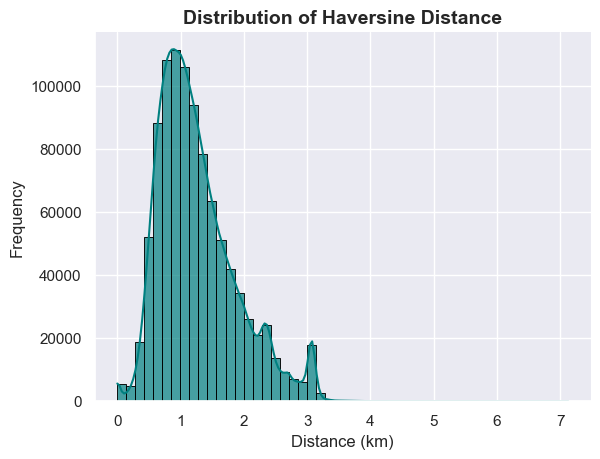

In [35]:
sns.histplot(np.log1p(df_clean['haversine_distance']), bins=50, color='teal', kde=True, edgecolor='black', alpha=0.7)
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Haversine Distance', fontsize=14, fontweight='bold')
sns.despine()  # removes the top/right border lines, cleaner look
plt.show()

In [36]:
zero_dist = (df_clean['haversine_distance'] == 0).sum()
print(f"Zero-distance trips: {zero_dist}")
print(f"\nTrips over 100km: {(df_clean['haversine_distance'] > 100).sum()}")
print(f"Trips over 50km: {(df_clean['haversine_distance'] > 50).sum()}")


Zero-distance trips: 2822

Trips over 100km: 13
Trips over 50km: 63


In [37]:
print(f"Before: {len(df_clean)}")

df_clean = df_clean[
    (df_clean['haversine_distance'] > 0) &
    (df_clean['haversine_distance'] <= 50)
]

print(f"After: {len(df_clean)}")

Before: 985691
After: 982806


In [38]:
sns.set_theme(style='whitegrid')
custom_colors = ['#4C9BE8', '#F2B134', '#4CAF50', '#E85D5D', '#9B59B6']  # approximate

# sns.countplot(x='', data=df_clean, palette=custom_colors)

In [39]:
sample=df_clean.sample(10000, random_state=314)

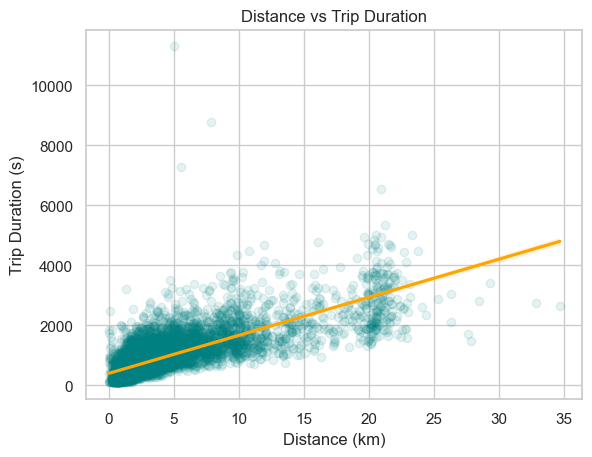

In [40]:
sns.regplot(x='haversine_distance', y='trip_duration', data=sample,
            scatter_kws={'alpha':0.1, 'color':'teal'},
            line_kws={'color':'orange'})
plt.xlabel('Distance (km)')
plt.ylabel('Trip Duration (s)')
plt.title('Distance vs Trip Duration')
plt.show()

In [41]:
custom_palette = ['#008080', '#FFA500']  # teal, orange
sns.set_palette(custom_palette)

In [42]:
short_trips = sample[sample['haversine_distance'] <= 10]

len(short_trips)

9365

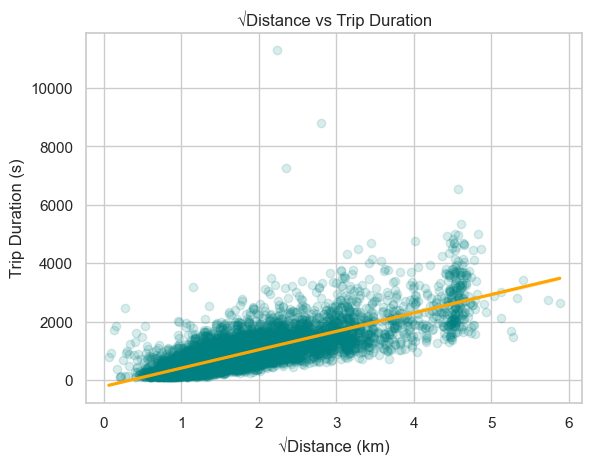

In [43]:
sample['sqrt_distance'] = np.sqrt(sample['haversine_distance'])

sns.regplot(x='sqrt_distance', y='trip_duration', data=sample,
            scatter_kws={'alpha':0.15, 'color': custom_palette[0]},
            line_kws={'color': custom_palette[1]})
plt.xlabel('√Distance (km)')
plt.ylabel('Trip Duration (s)')
plt.title('√Distance vs Trip Duration')
plt.show()

In [44]:
df_clean.columns

Index(['month', 'hour', 'day_of_week', 'vendor_id', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration',
       'haversine_distance'],
      dtype='object')

In [45]:
# This feature is not available at test time, we won't because it depends on the internet connection
df_clean = df_clean.drop(columns=['store_and_fwd_flag'])

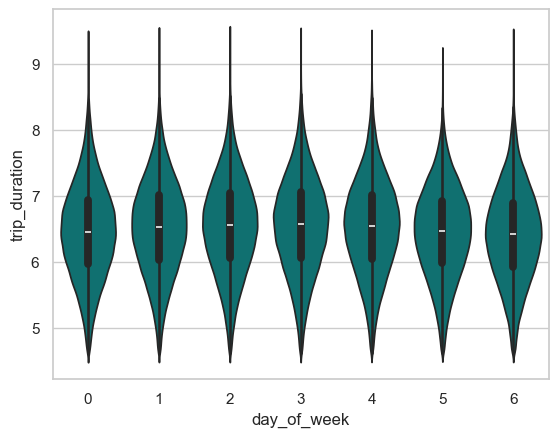

In [46]:
sns.violinplot(x='day_of_week', y=np.log1p(df_clean['trip_duration']), data=df_clean)
plt.show()

In [46]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 982806 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype   
---  ------              --------------   -----   
 0   month               982806 non-null  int32   
 1   hour                982806 non-null  int32   
 2   day_of_week         982806 non-null  int32   
 3   vendor_id           982806 non-null  category
 4   passenger_count     982806 non-null  int64   
 5   pickup_longitude    982806 non-null  float64 
 6   pickup_latitude     982806 non-null  float64 
 7   dropoff_longitude   982806 non-null  float64 
 8   dropoff_latitude    982806 non-null  float64 
 9   trip_duration       982806 non-null  int64   
 10  haversine_distance  982806 non-null  float64 
dtypes: category(1), float64(5), int32(3), int64(2)
memory usage: 72.2 MB


In [181]:
df_model = pd.get_dummies(df_clean, columns=['vendor_id'], drop_first=True)

#### Let's Re-profile the cleaned data with the added variables

In [51]:
profile = ProfileReport(df_clean, title="NYC Trip Duration  - 2nd Cleaned Data Profile", explorative=True)
profile.to_file(out / "cleaned_data_profile.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████████| 11/11 [00:00<00:00, 11.78it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]